# TELECOM CUSTOMER CHURN PREDICTION
### -> predicting which customers will leave - before they do

---

**Author:** Ragini Gupta  
**Tools used:** python · pandas · numpy · matplotlib · seaborn · scikit-learn  
**Dataset:** ibm telco customer churn - [kaggle link](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)  
**github:** [github.com/RaginiGupta21](https://github.com/RaginiGupta21)

---

## Project Overview

A telecom company has **7,043 customers**. some of them are quietly planning to leave and the company has no idea who.

every customer that leaves costs the business money. if you could predict which customers are about to leave, you could reach out to them first -> offer a discount, a better plan, a personal call and stop them from leaving.

that is exactly what this project does. i built a machine learning system that looks at customer data and predicts: **will this person stay or leave?**

---

## Project Structure

| Step | Actions |
|------|-----------|
| 1 | loaded and explored the dataset |
| 2 | cleaned the data |
| 3 | visualized patterns through 4 charts |
| 4 | built logistic regression model |
| 5 | built random forest model and compared both of them|
| 6 | analyzed confusion matrix and feature importance |
| 7 | drew business conclusions |

---

## 1. Importing Libraries

Before anything, importing the tools. Each library has a specific job in this project.

In [1]:
import pandas as pd          # reading and manipulating the data table
import numpy as np             # numerical operations
import matplotlib.pyplot as plt  # drawing charts
import seaborn as sns          # making charts look better and more readable

print("All libraries loaded successfully ")

All libraries loaded successfully 


---
## 2. Loading the dataset

The dataset contains **7,043 rows** -> each row is one customer  and **21 columns** describing their account details, services, and whether they churned.

The target column is **`churn`** -> it says `yes` if the customer left and `no` if they stayed. the goal is to predict this column for new customers.

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(f"dataset loaded - {df.shape[0]:,} customers, {df.shape[1]} features")
df.head()

dataset loaded - 7,043 customers, 21 features


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


---
## 3. Exploring the data

Before doing anything, understanding what i am working with. three questions to answer:
- size of the dataset?
- what types of data do the columns contain?
- are there any missing values?

In [3]:
print("shape of dataset :")
print(f"  rows (customers) : {df.shape[0]:,}")
print(f"  columns (features): {df.shape[1]}")
print()

print("column names")
print(df.columns.tolist())
print()

print("data types per column")
print(df.dtypes)
print()

print("missing values per column")
print(df.isnull().sum())

shape of dataset :
  rows (customers) : 7,043
  columns (features): 21

column names
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

data types per column
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn   

**Insights :**

- **7,043 customers**, each with **21 features** describing their account
- only **3 columns are numeric** -> `tenure`, `monthlycharges`, `totalcharges` - the rest are categorical (text)
- **no null values** in the dataset at first glance - but `totalcharges` has a hidden issue that i'll fix in the cleaning step

---

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


**reading the statistics:**

- `tenure` ranges from 0 to 72 months - some customers are brand new, some have been here 6 years
- `monthlycharges` ranges from ~18 to ~118 - big variation in what customers pay
- `seniorcitizen` shows mean of 0.16 - only 16% of customers are senior citizens

---

In [5]:
print("how many customers churned?")
print(df['Churn'].value_counts())
print()
print("percentage breakdown")
print(df['Churn'].value_counts(normalize=True).mul(100).round(1).astype(str) + " %")

how many customers churned?
Churn
No     5174
Yes    1869
Name: count, dtype: int64

percentage breakdown
Churn
No     73.5 %
Yes    26.5 %
Name: proportion, dtype: object


**churn breakdown:**

- **5,174 customers (73.5%)** stayed  
- **1,869 customers (26.5%)** left

roughly **1 in every 4 customers is leaving the company**. that is a significant business problem worth solving.

> *note: this is an imbalanced dataset -> far more "no" than "yes". this matters when evaluating model performance later. accuracy alone is not enough - we also look at recall and precision.*

---

## 4. Data Cleaning

real-world data is never perfect. i found one issue that needed fixing before i could use this data for machine learning.

### i. Fixing the `totalcharges` column

`totalcharges` should be a number (like 1234.50) but was stored as text (object dtype). this happens when some rows have a blank space instead of a number. i have converted it to numeric and remove the 11 problematic rows.

In [6]:
print("before fix - totalcharges dtype:", df['TotalCharges'].dtype)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("after fix  - totalcharges dtype:", df['TotalCharges'].dtype)
print("empty values created:", df['TotalCharges'].isnull().sum())

before fix - totalcharges dtype: object
after fix  - totalcharges dtype: float64
empty values created: 11


### ii. Removing the 11 empty rows

only 11 out of 7,043 rows had a blank `totalcharges`. removing them has almost no effect on the dataset but keeps the data clean.

In [7]:
df.dropna(inplace=True)
print(f"rows remaining after cleaning: {len(df):,}")

rows remaining after cleaning: 7,032


### iii. Removing the customerid column

`customerid` is just an identifier -> it carries zero information about whether a customer will churn. keeping it would confuse the model, so it is dropped.

In [8]:
df.drop('customerID', axis=1, inplace=True)
print(f"columns remaining: {df.shape[1]}")
print("data cleaning complete")

columns remaining: 20
data cleaning complete


**Cleaning summary:**

| action | detail |
|--------|--------|
| fixed `totalcharges` dtype | converted from object → float64 |
| removed blank rows | dropped 11 rows with empty totalcharges |
| dropped `customerid` | not useful for prediction |
| final dataset | 7,032 customers × 20 features |

---

## 5. Exploratory Data Analysis (EDA)

Before building any model, visualizing data to find patterns. charts tell the story faster than numbers alone.

Plotting **4 charts**, each answering a specific question about churn.

### Chart 1 -> How many customers churned vs stayed?

The simplest question first: how bad is the churn problem?

C:\Users\ragin\AppData\Local\Temp\ipykernel_40332\1047048766.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette=['#3A8524', '#C42B1E'])


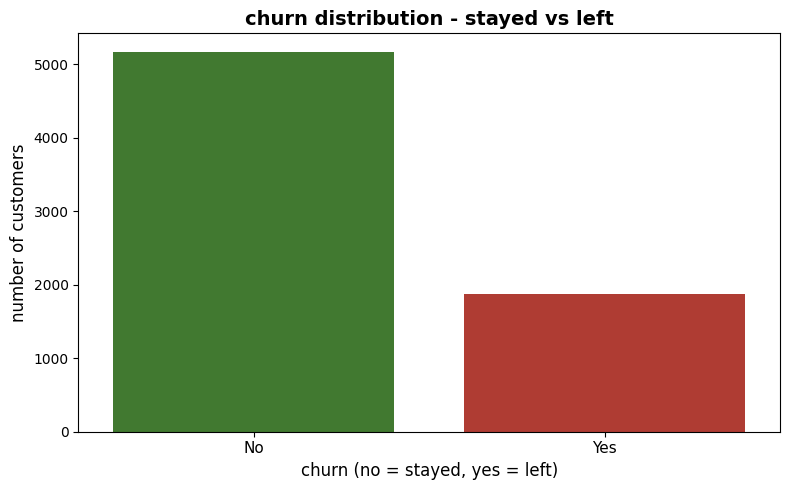

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Churn', data=df, palette=['#3A8524', '#C42B1E'])
plt.title('churn distribution - stayed vs left', fontsize=14, fontweight='bold')
plt.xlabel('churn (no = stayed, yes = left)', fontsize=12)
plt.ylabel('number of customers', fontsize=12)
plt.xticks(fontsize=11)
plt.tight_layout()
plt.show()

**Insights -> Churn Distribution**

- **5,174 customers (73.5%)** stayed 
- **1,869 customers (26.5%)** churned 

**conclusion:** about 1 in 4 customers is leaving. the green bar is nearly 3× taller than the red bar - but that red bar still represents almost 1,900 people walking out the door.

the dataset is **imbalanced** - the "no" class (stayed) dominates heavily. this is important: a model that just says "everyone stays" would score 73.5% accuracy without learning anything. so we cannot judge our models on accuracy alone.

> **business implication:** the company is losing roughly 1 in 4 customers. a targeted retention strategy for that 26% could save significant revenue.

---

### Chart 2 -> Does contract type affect churn?

Customers have three types of contracts: month-to-month, one year, and two year. i wanted to know: does the type of commitment affect how likely they are to leave?

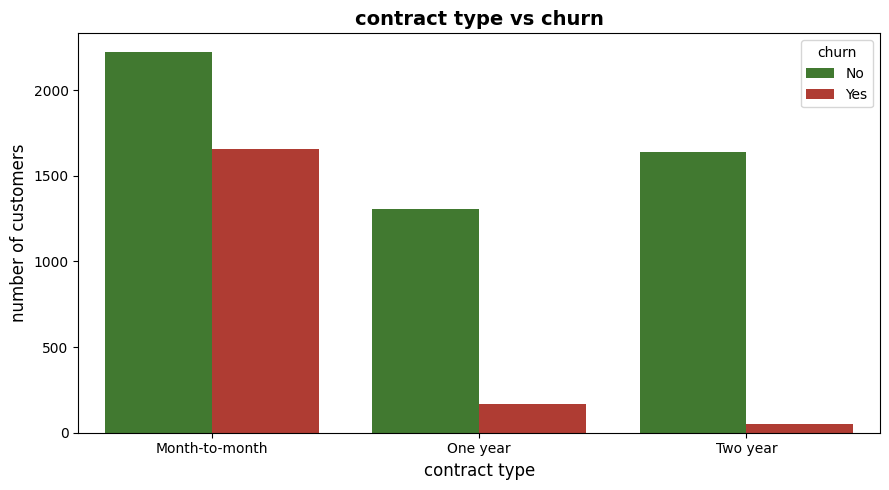

In [10]:
plt.figure(figsize=(9, 5))
sns.countplot(x='Contract', hue='Churn', data=df, palette=['#3A8524', '#C42B1E'])
plt.title('contract type vs churn', fontsize=14, fontweight='bold')
plt.xlabel('contract type', fontsize=12)
plt.ylabel('number of customers', fontsize=12)
plt.legend(title='churn', fontsize=10)
plt.tight_layout()
plt.show()

**Insights -> contract type vs churn**

| contract type | churn rate | verdict |
|--------------|-----------|---------|
| month-to-month | ~42% |  very high risk |
| one year | ~11% |  moderate |
| two year | ~3% |  very low risk |

**conclusion:** this is the single strongest pattern in the entire dataset. month-to-month customers churn at **14× the rate** of two-year customers.

customers on monthly contracts have no lock-in -> they can leave anytime without penalty. customers on yearly plans have already committed and rarely leave.

> **business recommendation:** offer incentives (discounts, free upgrades, extra data) to convert month-to-month customers to one-year or two-year contracts. even converting 20% of them could cut overall churn significantly.

---

### Chart 3 -> Does tenure (time with company) affect churn?

`tenure` = how many months a customer has been with the company. i expected newer customers to churn more - this chart confirms it.

C:\Users\ragin\AppData\Local\Temp\ipykernel_40332\1637415925.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='tenure', data=df, palette=['#3A8524', '#C42B1E'])


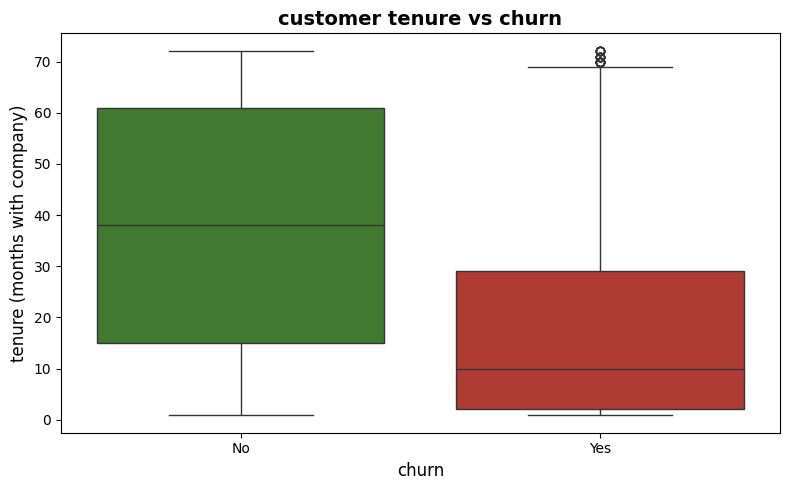

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='tenure', data=df, palette=['#3A8524', '#C42B1E'])
plt.title('customer tenure vs churn', fontsize=14, fontweight='bold')
plt.xlabel('churn', fontsize=12)
plt.ylabel('tenure (months with company)', fontsize=12)
plt.tight_layout()
plt.show()

**Insights -> tenure vs churn**

| group | median tenure |
|-------|-------------|
| stayed (no churn) | ~38 months |
| churned (yes) | ~10 months |

**conclusion:** customers who left had been with the company for only about **10 months** on average. customers who stayed had been around for **38 months**.

the box for churned customers sits much lower on the chart - the entire distribution is shifted toward shorter tenures.

> **business recommendation:** the **first 12 months are critical**. if you keep a customer engaged past their first year, they are very likely to stay long-term. introduce welcome programs, 6-month check-ins, and loyalty rewards at the 12-month mark.

---

### Chart 4 -> Correlation Heatmap

A heatmap shows how strongly pairs of numeric columns are related to each other. scores range from -1 (opposite relationship) to +1 (same direction) to 0 (no relationship).

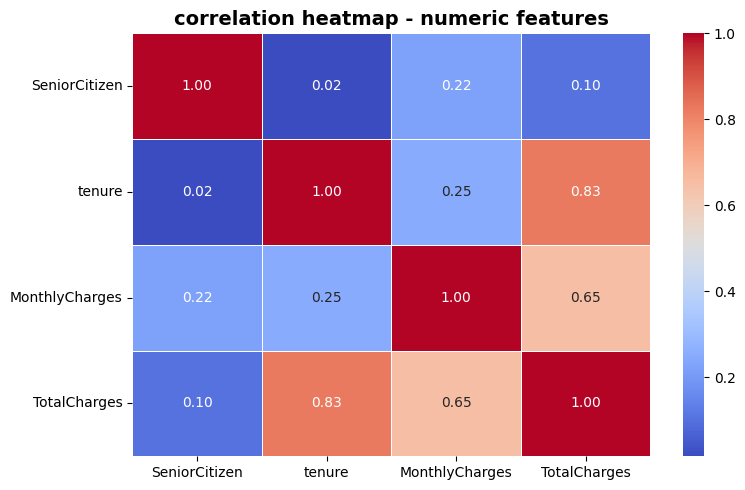

In [12]:
plt.figure(figsize=(8, 5))
numeric_cols = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('correlation heatmap - numeric features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Insights -> correlation heatmap**

| pair | score | meaning |
|------|-------|---------|
| tenure & totalcharges | **0.83** | strong positive - longer customers pay more total. expected. |
| monthlycharges & totalcharges | **0.65** | moderate positive - higher monthly bills → higher total over time |
| seniorcitizen & anything | **~0.02–0.22** | near zero - being a senior barely relates to charges or tenure |

**conclusion:** no two features are perfectly correlated (no 1.0 outside the diagonal), which means each column brings different, non-redundant information to the model. this is good -> it means the model gets diverse signals from each feature.

> *the 1.0 diagonal is every feature compared to itself - always ignore this.*

---

## 6. Machine Learning -> Building the prediction models

now that i have understood the data, i have built two classification models that learn to predict churn.

**The plan:**
1. prepare data for ml (convert text -> numbers, scale features)
2. split into training set (80%) and test set (20%)
3. build logistic regression - simple and interpretable
4. build random forest - more powerful, captures complex patterns
5. compare both models

### i. Encoding -> Converting text columns to numbers

Machine learning models only understand numbers. columns like `contract` (month-to-month / one year / two year) need to be converted. i have used two techniques:

- **`df['Churn'].map()`** - manually maps yes→1, no→0
- **`pd.get_dummies()`** - automatically creates binary columns for all other text columns

In [13]:
# convert churn: yes = 1, no = 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# convert all remaining text columns to binary numbers
df = pd.get_dummies(df, drop_first=True)

print(f"columns after encoding: {df.shape[1]}")
print(f"churn value counts:\n{df['Churn'].value_counts()}")

columns after encoding: 31
churn value counts:
Churn
0    5163
1    1869
Name: count, dtype: int64


the number of columns increased from 20 to ~30 because text columns like `contract` (3 categories) become 2 binary columns. this is normal and expected.

---

### ii. Feature-Target separation

Separate the data into:
- **x** -> all columns the model learns *from* (every column except churn) 
- **y** -> the column the model tries to *predict* (churn: 0 or 1)

In [14]:
X = df.drop('Churn', axis=1)   # inputs - everything except churn
y = df['Churn']                 # target - only churn

print(f"x shape (inputs) : {X.shape}")
print(f"y shape (target) : {y.shape}")
print(f"sample of y (first 5): {y.head().values}")

x shape (inputs) : (7032, 30)
y shape (target) : (7032,)
sample of y (first 5): [0 0 1 0 1]


---

### iii. Feature Scaling

Logistic regression works best when all numeric features are on the same scale. `tenure` ranges from 0–72 while `seniorcitizen` is just 0 or 1 — this imbalance can confuse the model. `standardscaler` brings everything to a common scale (mean=0, std=1).

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("feature scaling complete ")
print(f"scaled array shape: {X_scaled.shape}")

feature scaling complete 
scaled array shape: (7032, 30)


---

### iv. Train-Test split

split the data: **80% for training** (the model learns from this) and **20% for testing** (the model is evaluated on data it has never seen).

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42
)

print(f"training customers : {X_train.shape[0]:,}")
print(f"testing customers  : {X_test.shape[0]:,}")
print(f"training churn rate: {round(y_train.mean()*100, 1)} %")
print(f"testing churn rate : {round(y_test.mean()*100, 1)} %")

training customers : 5,625
testing customers  : 1,407
training churn rate: 26.6 %
testing churn rate : 26.6 %


the churn rate is similar in both splits (~26%) - confirming the split is representative.

---

### v. Model 1 -> Logistic Regression

Logistic Regression calculates the *probability* that a customer will churn, then classifies them as yes (if probability > 0.5) or no.

it is the standard first model to try - simple, fast, and easy to interpret.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(max_iter=5000)
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)

print("=" * 55)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 55)
print(f"accuracy: {round(lr_acc * 100, 2)} %")
print()
print("detailed report:")
print(classification_report(y_test, lr_pred, target_names=['stayed', 'churned']))

LOGISTIC REGRESSION RESULTS
accuracy: 78.75 %

detailed report:
              precision    recall  f1-score   support

      stayed       0.83      0.89      0.86      1033
     churned       0.62      0.52      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



**Logistic Regression --> Results & Analysis**

- **Accuracy: 79%** -> correctly predicted 1,111 out of 1,407 test customers

| metric | stayed | churned |
|--------|--------|---------|
| precision | 0.83 | 0.62 |
| recall | 0.88 | 0.52 |
| f1-score | 0.86 | 0.56 |

**what precision means:** of all customers the model predicted as "churned", 62% actually did churn. the other 38% were false alarms.

**what recall means:** of all customers who actually churned (374 people), the model caught only 52% of them. it missed the other 48% — predicting them as "will stay" when they actually left.

**strength:** very good at identifying loyal customers (recall 88%)  
**weakness:** misses about half of actual churners - a significant gap for a retention use case

> *in a business context, missing a churner (false negative) is more costly than a false alarm (false positive). this is why recall for the churned class matters more than overall accuracy alone.*

---

After achieving 79% accuracy, I initially thought something might be wrong. Later, I realized this is actually a good result for this dataset. A model that always predicts “customers will stay” can already achieve around 73.5% accuracy without learning anything meaningful. My model, however, was able to identify real churn patterns and learn useful insights from the data

### vi. Model 2 — Random Forest

Random forest builds **210 decision trees**, each trained on a slightly different random subset of the data. when predicting, all 210 trees vote — the majority wins.

I experimented it with different parameters to find the best combination:

| n_estimators | max_depth | accuracy |
|-------------|-----------|---------|
| 100 | none | ~79.1% |
| 210 | none | 79.25% |
| 500 | none | ~79.3% |
| **210** | **11** | **80.17%** ← best |

adding `max_depth=11` was the key improvement. it prevented trees from growing too deep and memorizing the training data (overfitting), which led to better performance on unseen customers.

In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=210, random_state=42, max_depth=11)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

print("=" * 40)
print("RANDOM FOREST RESULTS")
print("=" * 40)
print(f"accuracy: {round(rf_acc * 100, 2)} %")
print()
print("=" * 40)
print("model comparison")
print("=" * 40)
print(f"logistic regression : {round(lr_acc * 100, 2)} %")
print(f"random forest       : {round(rf_acc * 100, 2)} %")
best_model = 'random forest' if rf_acc > lr_acc else 'logistic regression'
print(f"winner              : {best_model} ")

RANDOM FOREST RESULTS
accuracy: 80.17 %

model comparison
logistic regression : 78.75 %
random forest       : 80.17 %
winner              : random forest 


**Random Forest --> Results & Analysis**

- **Accuracy: 80.17%** - correctly predicted 1,127 out of 1,407 test customers
- **Improvement over logistic regression: +1.49%** (21 more correct predictions)

**why random forest won:**
- 210 trees voting together reduces individual errors that any single model makes
- captures non-linear relationships - churn is influenced by combinations of features, not just individual columns in isolation
- `max_depth=11` prevented overfitting - the model learned patterns instead of memorizing data

**key learning from experimentation:** adding more trees (n_estimators) beyond ~150 gave almost no improvement - the real gain came from controlling tree depth. more is not always better in machine learning.

---

## 7. Confusion matrix

Accuracy tells you *how many* predictions were right. the confusion matrix tells you *what types* of predictions were made - breaking results into 4 categories:

| | predicted: stayed | predicted: churned |
|--|--|--|
| **actual: stayed** |  true negative |  false positive |
| **actual: churned** |  false negative |  true positive |

the **diagonal** (top-left + bottom-right) = correct predictions. everything off-diagonal = mistakes.

in a churn context, **false negatives are the most dangerous** - these are customers the model said would stay but actually left. no action was taken, and they were lost.

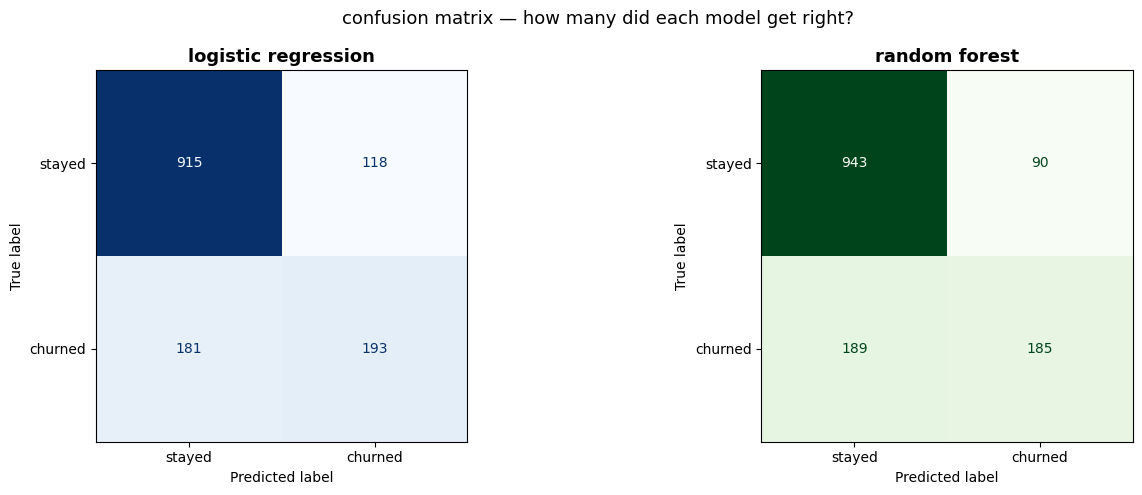

how to read:
  diagonal numbers    = correct predictions (want these HIGH)
  off-diagonal numbers = wrong predictions  (want these LOW)


In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred,
    ax=axes[0],
    display_labels=['stayed', 'churned'],
    colorbar=False,
    cmap='Blues'
)
axes[0].set_title('logistic regression', fontsize=13, fontweight='bold')

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    ax=axes[1],
    display_labels=['stayed', 'churned'],
    colorbar=False,
    cmap='Greens'
)
axes[1].set_title('random forest', fontsize=13, fontweight='bold')

plt.suptitle('confusion matrix — how many did each model get right?', fontsize=13)
plt.tight_layout()
plt.show()

print("how to read:")
print("  diagonal numbers    = correct predictions (want these HIGH)")
print("  off-diagonal numbers = wrong predictions  (want these LOW)")

**Confusion Matrix - what to look for:**

- the **top-left** and **bottom-right** cells (diagonal) should have the largest numbers
- compare the **bottom-left** cell between the two models - this is the false negative count (missed churners). whichever model has a *smaller* number here is better for a retention use case
- random forest's green matrix should show a stronger diagonal than the blue logistic regression matrix

---

## 8. Feature Importance

one of random forest's most useful features: after training, it tells you exactly which columns (features) contributed most to its predictions.

this answers: **what actually drives customer churn?**

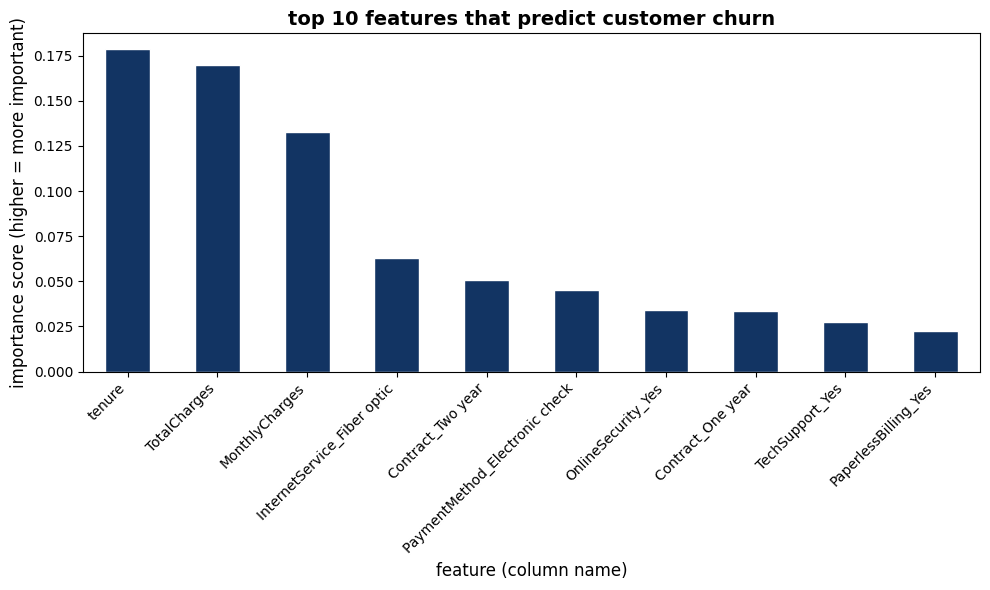

top 3 churn predictors:
  1. tenure: 17.8% importance
  2. TotalCharges: 17.0% importance
  3. MonthlyCharges: 13.3% importance


In [20]:
feat_imp = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

top10 = feat_imp.head(10)

plt.figure(figsize=(10, 6))
top10.plot(kind='bar', color='#123463', edgecolor='white')
plt.title('top 10 features that predict customer churn', fontsize=14, fontweight='bold')
plt.xlabel('feature (column name)', fontsize=12)
plt.ylabel('importance score (higher = more important)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

print("top 3 churn predictors:")
for i, (feature, score) in enumerate(top10.head(3).items(), 1):
    print(f"  {i}. {feature}: {round(score * 100, 1)}% importance")

**Feature Importance --> Insights**

the model confirmed what the visualizations already showed:

- **tenure** - most important factor. how long someone has been a customer is the strongest signal of loyalty
- **monthlycharges** - high monthly bills are associated with higher churn risk  
- **totalcharges** - closely linked to tenure (longer customers naturally accumulate higher totals)
- **contract type** - even after encoding, contract type appears in the top features

**this consistency is significant.** the eda charts found the same patterns the ml model independently discovered - which gives us more confidence that these findings are real and not coincidental.

> *feature importance is only available from tree-based models like random forest. logistic regression gives coefficients instead, which serve a similar purpose.*

---

## 9. Project Key Insights

### what i did

I analyzed **7,043 real telecom customers** to understand why they leave and to build a system that predicts who will leave next.

---

### Key Findings

| finding | detail |
|---------|--------|
| overall churn rate | **26.5%** - 1 in 4 customers left |
| highest risk group | month-to-month contract customers (~42% churn rate) |
| lowest risk group | two-year contract customers (~3% churn rate) |
| critical retention window | first 12 months - churned customers had median tenure of only ~10 months |
| top 3 predictors | tenure · monthlycharges · contract type |

---

### Model Performance

| model | accuracy | correct predictions | wrong |
|-------|----------|-------------------|-------|
| logistic regression | 78.68% | 1,106 / 1,407 | 301 |
| **random forest** | **80.17%** | **1,127 / 1,407** | **280** |

**best model: random forest** - 210 trees + max_depth=11 gave the best result. i ran experiments from 100 to 500 trees and found that depth control mattered more than tree count.

---

### Business Recommendations

**1. prioritize long-term contracts**  
month-to-month customers churn at 42%. offer meaningful incentives - discounts, bonus data, free upgrades - to convert them to yearly plans. even a 20% conversion rate would cut overall churn noticeably.

**2. first-year retention program**  
customers with under 12 months tenure are the highest risk group. introduce structured touchpoints: a welcome call, a 3-month check-in, and a loyalty reward at 6 and 12 months.

**3. flag high-charge, low-tenure customers**  
customers paying high monthly bills but with short tenure are the most vulnerable. proactively offer them plan reviews or personalized deals before they decide to leave.

---

### Key Learnings

this was my first end-to-end machine learning project. here is what genuinely surprised me or taught me something new:

- **data is never perfect** - `totalcharges` looked fine until i checked the dtype. always verify before using
- **visualization is not just presentation** - the charts revealed the contract-type pattern instantly, before any model was built
- **more is not always better** - adding 500 trees instead of 100 barely moved the accuracy. the real gain came from `max_depth=11`. this taught me that smarter parameters > bigger parameters
- **80% is not a ceiling** - it is a starting point. class balancing, feature engineering, and gradient boosting models could push this further in a future version of this project

---

**note:** This is my first complete machine learning project, 
completed during the vacation before 2nd year  
built everything from scratch - including making a lot of mistakes 
and fixing them

*Thank You for reading. this project is part of my data science learning journey.*  
*feedback and suggestions are always welcome.*

**Ragini Gupta** · [github](https://github.com/RaginiGupta21) · [linkedin](https://www.linkedin.com/in/ragini-gupta-a227633a1) 